### Finding 1: NAV trend
Over Jan 2022 to May 2026, funds diverged sharply. Debt and liquid funds grew slowly and steadily (about 100 to 130), while equity funds ranged from roughly 100 to over 350, showing higher risk and higher reward.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path("..").resolve()
conn = sqlite3.connect(BASE / "Data" / "db" / "bluestock_mf.db")

CHART_DIR = BASE / "Reports" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

nav = pd.read_sql_query(
    "SELECT amfi_code, date, nav FROM fact_nav",
    conn, parse_dates=["date"]
)
nav.head()

,amfi_code,date,nav
0,100016,2022-01-03,520.4608
1,100016,2022-01-04,515.0971
2,100016,2022-01-05,521.7239
3,100016,2022-01-06,515.7880
4,100016,2022-01-07,515.1639


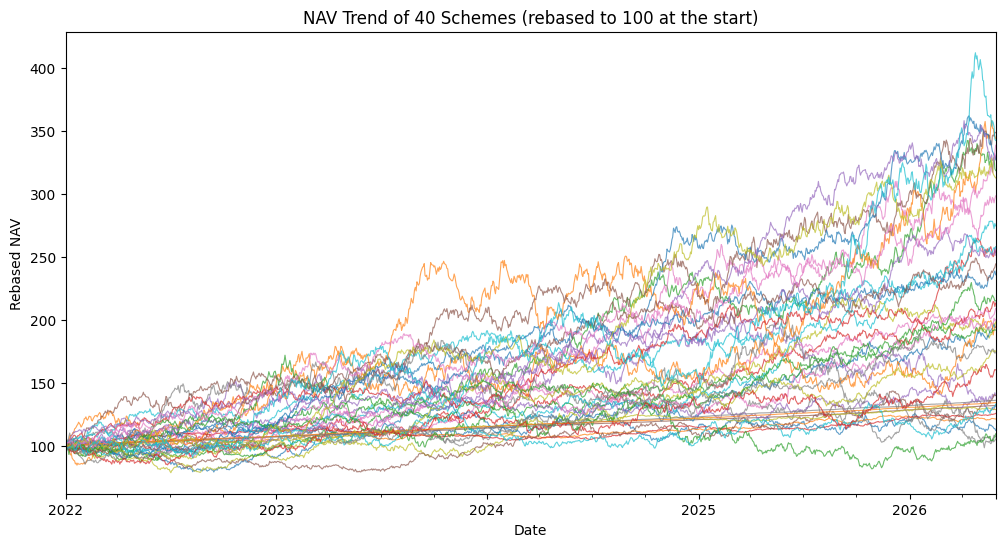

In [2]:
wide = nav.pivot(index="date", columns="amfi_code", values="nav")
rebased = wide / wide.bfill().iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 6))
rebased.plot(ax=ax, legend=False, linewidth=0.8, alpha=0.7)
ax.set_title("NAV Trend of 40 Schemes (rebased to 100 at the start)")
ax.set_xlabel("Date")
ax.set_ylabel("Rebased NAV")
fig.savefig(CHART_DIR / "01_nav_trend.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 2: AUM growth by fund house
All 10 fund houses grew their AUM every year from 2022 to 2025. SBI Mutual Fund leads and roughly doubled to Rs. 12.5 lakh crore. SBI, ICICI Prudential and HDFC together manage about half of the AUM of the top 10, so the industry is concentrated among a few large players.

year                      2022  2023   2024   2025
fund_house                                        
SBI Mutual Fund           6.30  8.45  11.14  12.50
ICICI Prudential MF       4.88  5.90   8.74  10.74
HDFC Mutual Fund          4.45  5.35   7.87   9.30
Nippon India MF           2.78  3.40   5.70   7.00
Kotak Mahindra MF         2.72  3.25   4.89   5.80
Aditya Birla Sun Life MF  2.85  3.08   3.84   4.60
UTI Mutual Fund           2.32  2.65   3.52   4.10
Axis Mutual Fund          2.40  2.60   3.00   3.50
Mirae Asset MF            1.08  1.42   2.10   2.90
DSP Mutual Fund           1.12  1.32   1.88   2.30


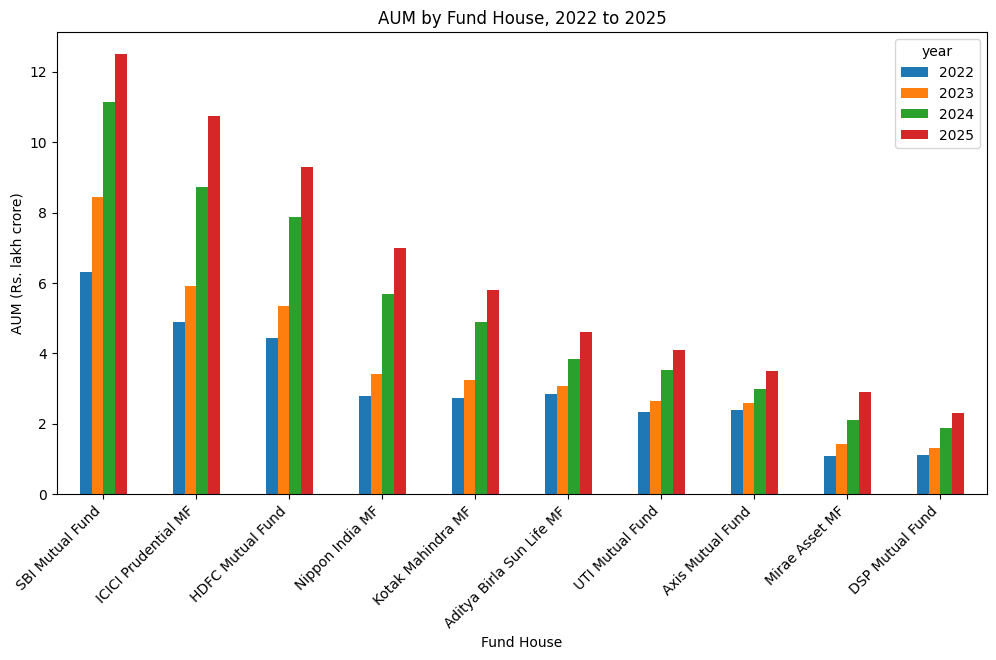

In [3]:
aum = pd.read_sql_query(
    "SELECT date, fund_house, aum_lakh_crore FROM fact_aum",
    conn, parse_dates=["date"]
)
aum["year"] = aum["date"].dt.year

# keep the latest reading of each year for each fund house
latest = aum.sort_values("date").groupby(["fund_house", "year"]).tail(1)
table = latest.pivot(index="fund_house", columns="year", values="aum_lakh_crore")
table = table.sort_values(table.columns[-1], ascending=False)
print(table)

fig, ax = plt.subplots(figsize=(12, 6))
table.plot(kind="bar", ax=ax)
ax.set_title("AUM by Fund House, 2022 to 2025")
ax.set_xlabel("Fund House")
ax.set_ylabel("AUM (Rs. lakh crore)")
plt.xticks(rotation=45, ha="right")
fig.savefig(CHART_DIR / "02_aum_growth.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 3: SIP inflow trend
Monthly SIP inflows rose from about Rs. 11,500 crore in Jan 2022 to a record Rs. 31,002 crore in Dec 2025, an increase of roughly 2.7 times. Growth was steady with only brief flat periods, showing that SIP investors keep investing through market ups and downs.

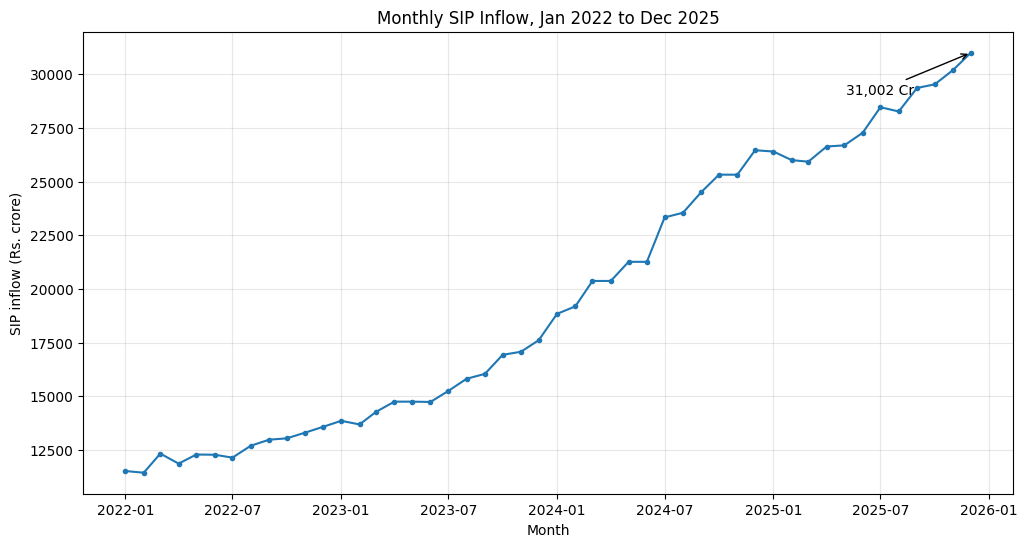

In [4]:
sip = pd.read_sql_query(
    "SELECT month, sip_inflow_crore FROM fact_sip_industry ORDER BY month",
    conn
)
sip["month"] = pd.to_datetime(sip["month"])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(sip["month"], sip["sip_inflow_crore"], marker="o", markersize=3)

last = sip.iloc[-1]
ax.annotate(
    f"{last['sip_inflow_crore']:,.0f} Cr",
    xy=(last["month"], last["sip_inflow_crore"]),
    xytext=(-90, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->"),
)

ax.set_title("Monthly SIP Inflow, Jan 2022 to Dec 2025")
ax.set_xlabel("Month")
ax.set_ylabel("SIP inflow (Rs. crore)")
ax.grid(alpha=0.3)
fig.savefig(CHART_DIR / "03_sip_inflow.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 4: Category inflows (FY 2024-25)
Liquid funds received by far the largest net inflows, about Rs. 32,000 to 42,000 crore every month, mostly short-term parking of cash. Among other categories, Sectoral/Thematic and Flexi Cap attracted the most, while ELSS received the least (about Rs. 500 crore a month). No category saw net outflows in any month.

(12, 12)


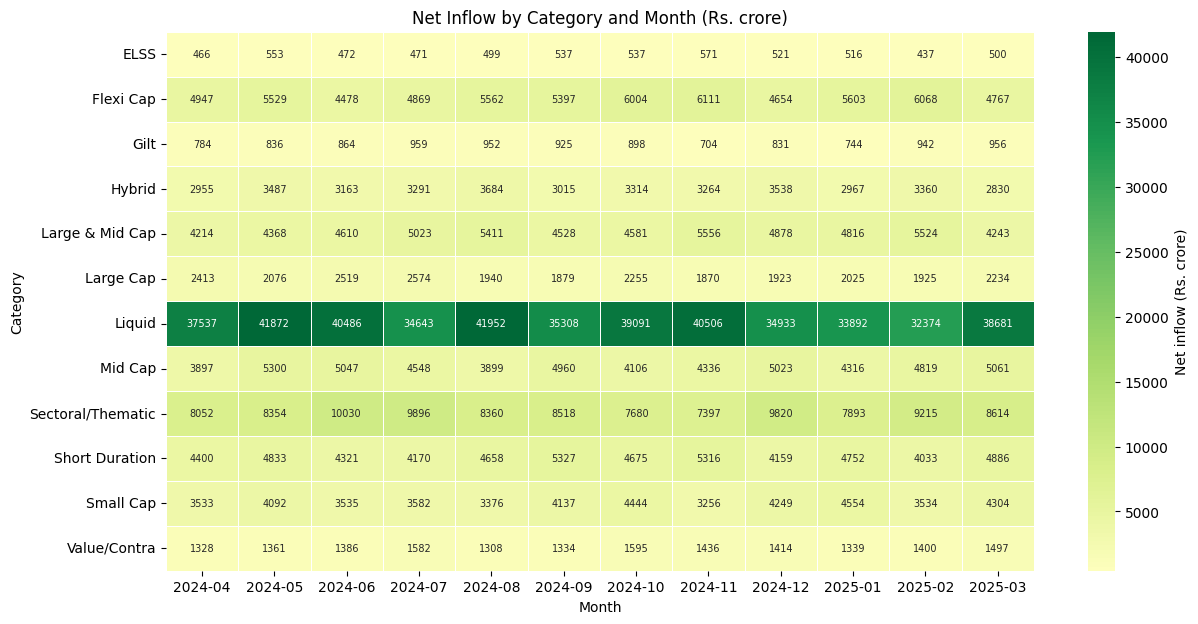

In [8]:
import seaborn as sns

cat = pd.read_sql_query(
    "SELECT month, category, net_inflow_crore FROM fact_category_inflows",
    conn
)
grid = cat.pivot(index="category", columns="month", values="net_inflow_crore")
grid = grid[sorted(grid.columns)]
print(grid.shape)

fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(grid, cmap="RdYlGn", center=0, annot=True, fmt=".0f",
            annot_kws={"size": 7}, linewidths=0.5, ax=ax,
            cbar_kws={"label": "Net inflow (Rs. crore)"})
ax.set_title("Net Inflow by Category and Month (Rs. crore)")
ax.set_xlabel("Month")
ax.set_ylabel("Category")
fig.savefig(CHART_DIR / "04_category_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 5: Investor demographics
Investors aged 26-35 form the largest group (40.7%), and investors under 36 make up about 56% of all investors, so mutual fund investing in this data is driven by younger people. Investors aged 46 and above are only about 20%. SIP amounts are very similar across age groups: the typical (median) SIP is about Rs. 5,000 for every group, and the 56+ group is only slightly higher. The average SIP (about Rs. 11,000) is more than double the median, which means a small number of large SIPs pull the average up. Age affects how many people invest much more than how much each person invests.

age_group
18-25     753
26-35    2033
36-45    1237
46-55     589
56+       388
Name: count, dtype: int64


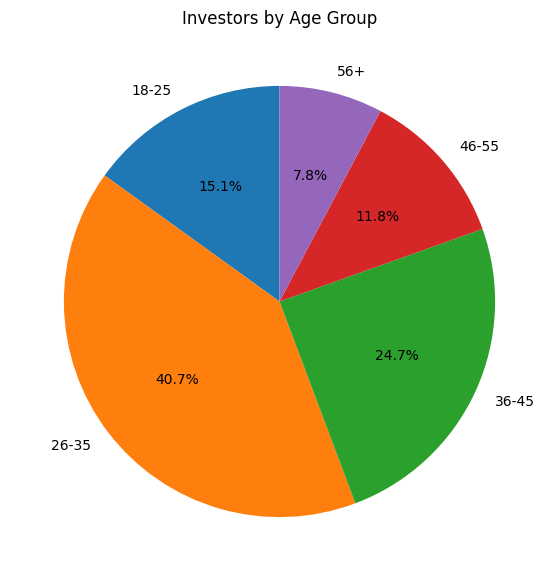

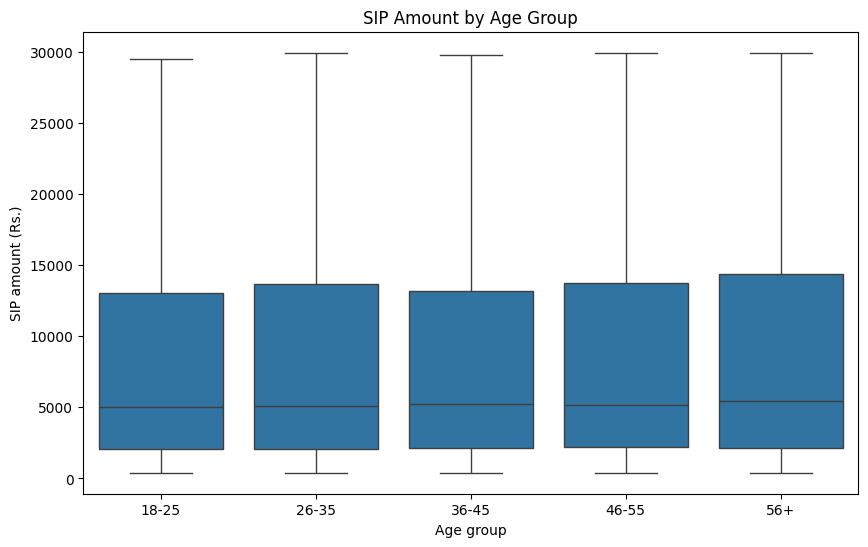

In [7]:
tx = pd.read_sql_query(
    "SELECT investor_id, age_group, transaction_type, amount_inr FROM fact_transactions",
    conn
)
order = ["18-25", "26-35", "36-45", "46-55", "56+"]

# Chart 5a: share of investors by age group
investors = tx.drop_duplicates("investor_id")
counts = investors["age_group"].value_counts().reindex(order)
print(counts)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
ax.set_title("Investors by Age Group")
fig.savefig(CHART_DIR / "05a_age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 5b: SIP amount by age group
sips = tx[tx["transaction_type"] == "SIP"]

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=sips, x="age_group", y="amount_inr", order=order,
            showfliers=False, ax=ax)
ax.set_title("SIP Amount by Age Group")
ax.set_xlabel("Age group")
ax.set_ylabel("SIP amount (Rs.)")
fig.savefig(CHART_DIR / "05b_sip_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 6: Geographic distribution
SIP investment is spread fairly evenly across the 12 states, with no single state dominating. Madhya Pradesh (about Rs. 2.07 crore) and Punjab (about Rs. 2.01 crore) have the highest total SIP amounts, while Maharashtra (about Rs. 1.64 crore) and Rajasthan (about Rs. 1.65 crore) have the lowest, a gap of about 26% between the highest and lowest state. By city tier, T30 (top 30) cities contribute about 65.9% of the total transaction amount and B30 cities about 34.1%, so smaller cities already bring in about one-third of the money, which is a large opportunity for distributors.

state
Maharashtra       1.64
Rajasthan         1.65
Delhi             1.71
West Bengal       1.75
Uttar Pradesh     1.75
Karnataka         1.77
Haryana           1.82
Gujarat           1.84
Tamil Nadu        1.84
Telangana         1.86
Punjab            2.01
Madhya Pradesh    2.07
Name: amount_inr, dtype: float64


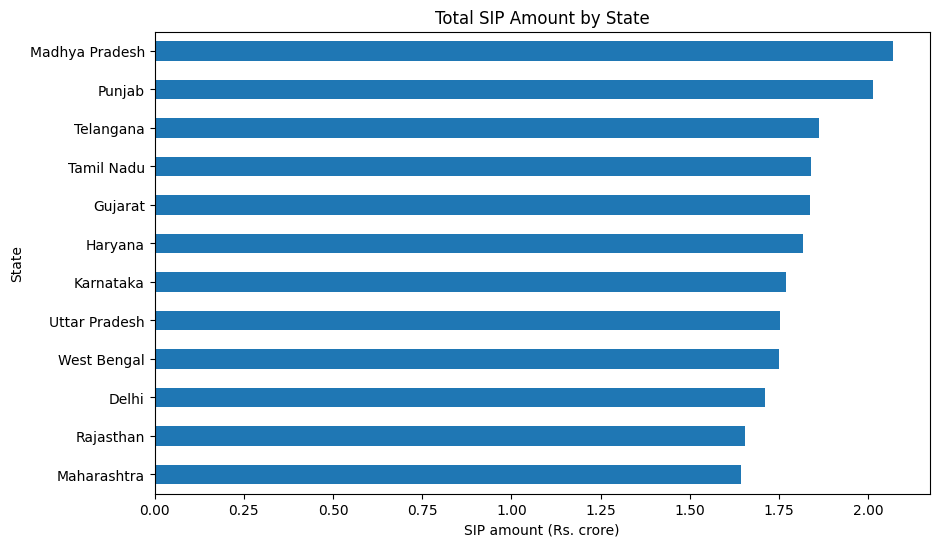

city_tier
B30    1202325640
T30    2319254790
Name: amount_inr, dtype: int64


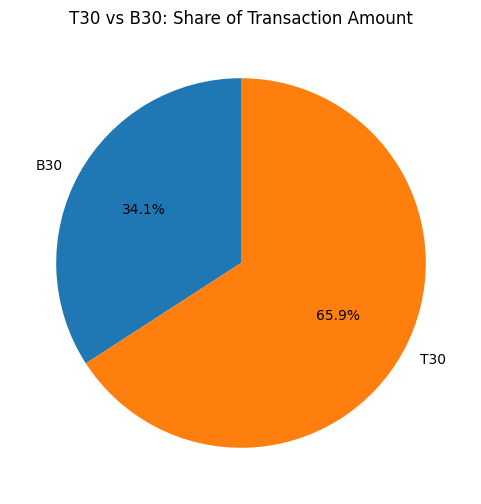

In [9]:
geo = pd.read_sql_query(
    "SELECT state, city_tier, transaction_type, amount_inr FROM fact_transactions",
    conn
)

# Chart 6a: total SIP amount by state
sip_state = (geo[geo["transaction_type"] == "SIP"]
             .groupby("state")["amount_inr"].sum()
             .sort_values() / 1e7)          # convert Rs. to Rs. crore
print(sip_state.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
sip_state.plot(kind="barh", ax=ax)
ax.set_title("Total SIP Amount by State")
ax.set_xlabel("SIP amount (Rs. crore)")
ax.set_ylabel("State")
fig.savefig(CHART_DIR / "06a_sip_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

# Chart 6b: T30 vs B30 share of total transaction amount
tier = geo.groupby("city_tier")["amount_inr"].sum()
print(tier)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(tier, labels=tier.index, autopct="%1.1f%%", startangle=90)
ax.set_title("T30 vs B30: Share of Transaction Amount")
fig.savefig(CHART_DIR / "06b_t30_b30.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 7: Folio count growth
The total number of mutual fund folios almost doubled between Jan 2022 and Dec 2025, rising from 13.26 crore to 26.12 crore, an increase of about 12.9 crore folios (about 97%). Growth was slow in 2022 (with a very small dip in mid-2022), accelerated from 2023, and was fastest through 2024. It continued in 2025 but at a gentler pace. The data points are published industry milestones, not every month. The overall rise is consistent with the growth in SIP inflows seen in Finding 3.

        month  total_folios_crore
0  2022-01-01               13.26
20 2025-12-01               26.12


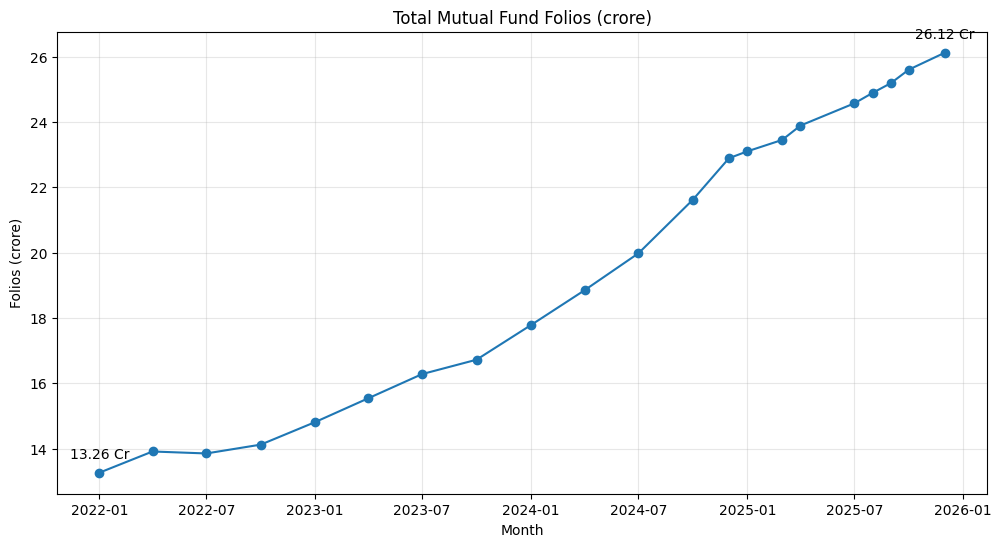

In [10]:
folio = pd.read_sql_query(
    "SELECT * FROM fact_folio_count ORDER BY month", conn
)
folio["month"] = pd.to_datetime(folio["month"])
print(folio[["month", "total_folios_crore"]].iloc[[0, -1]])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(folio["month"], folio["total_folios_crore"], marker="o")

first, last = folio.iloc[0], folio.iloc[-1]
for row in (first, last):
    ax.annotate(f"{row['total_folios_crore']:.2f} Cr",
                xy=(row["month"], row["total_folios_crore"]),
                xytext=(0, 10), textcoords="offset points", ha="center")

ax.set_title("Total Mutual Fund Folios (crore)")
ax.set_xlabel("Month")
ax.set_ylabel("Folios (crore)")
ax.grid(alpha=0.3)
fig.savefig(CHART_DIR / "07_folio_growth.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 8: Correlation of fund returns
The daily returns of the 10 selected funds are almost uncorrelated: every pair of different funds lies between about -0.08 and +0.05, and equity funds show no stronger link to each other than to the liquid funds. Real large-cap funds downloaded from mfapi.in show much stronger co-movement (correlations of about 0.77 to 0.91 for four of the six funds checked). This indicates that the daily NAV series in the provided dataset were generated independently for each fund, so these correlations should not be used to draw conclusions about diversification.

Funds picked: 10
Correlation grid size: (10, 10)


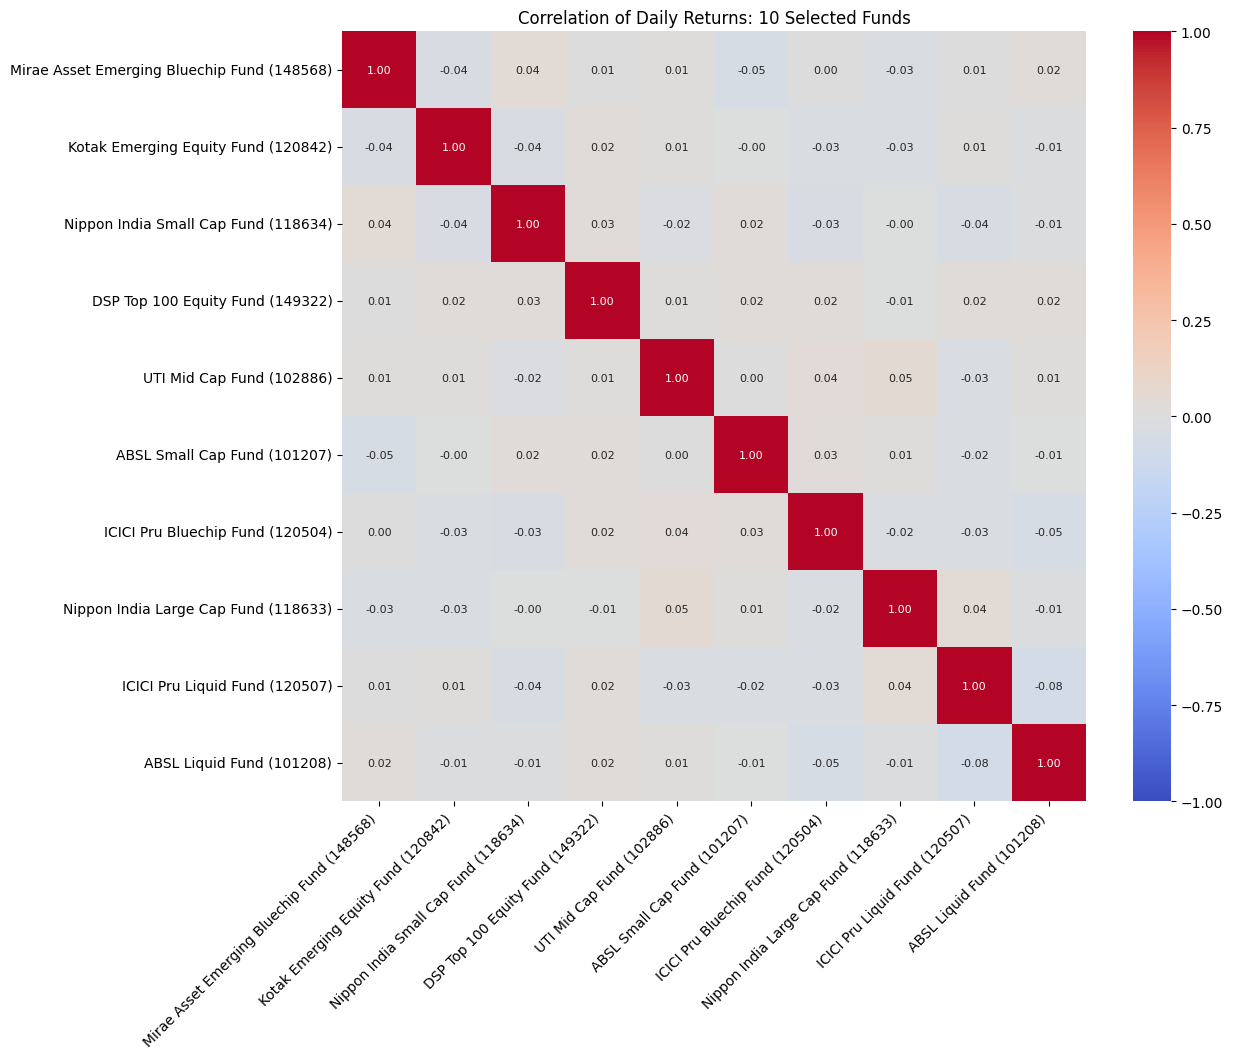


Average correlation among the 8 equity funds: 0.00
Average correlation between equity and debt funds: -0.01
Highest pair: UTI Mid Cap Fund (102886) and Nippon India Large Cap Fund (118633) = 0.05
Lowest pair:  ICICI Pru Liquid Fund (120507) and ABSL Liquid Fund (101208) = -0.08


In [16]:
import numpy as np
import seaborn as sns

# 1. Pick the funds: 8 largest equity + 2 largest debt (by AUM)
perf = pd.read_sql_query(
    """
    SELECT p.amfi_code, p.scheme_name, p.aum_crore, f.category
    FROM fact_performance p
    JOIN dim_fund f ON f.amfi_code = p.amfi_code
    """,
    conn
)
perf["amfi_code"] = perf["amfi_code"].astype(str)

eq = perf[perf["category"] == "Equity"].nlargest(8, "aum_crore")
debt = perf[perf["category"] == "Debt"].nlargest(2, "aum_crore")
picked = pd.concat([eq, debt])
print("Funds picked:", len(picked))

# 2. Readable labels (full short name + code)
labels = {
    row.amfi_code: row.scheme_name.split(" - ")[0][:34] + " (" + row.amfi_code + ")"
    for row in picked.itertuples()
}

# 3. Daily returns for those funds, one column per fund
rets = pd.read_sql_query(
    "SELECT amfi_code, date, daily_return_pct FROM fact_nav",
    conn, parse_dates=["date"]
)
rets["amfi_code"] = rets["amfi_code"].astype(str)
wide = rets.pivot(index="date", columns="amfi_code", values="daily_return_pct")
wide = wide[list(labels.keys())].rename(columns=labels)

# 4. Correlation grid (remove the extra axis names)
corr = wide.corr().rename_axis(None, axis=0).rename_axis(None, axis=1)
print("Correlation grid size:", corr.shape)

# 5. Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation of Daily Returns: 10 Selected Funds")
plt.xticks(rotation=45, ha="right")
fig.savefig(CHART_DIR / "08_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# 6. Summary numbers for the finding
cols = list(corr.columns)
eq_cols, debt_cols = cols[:8], cols[8:]
off_diag = ~np.eye(len(cols), dtype=bool)
pairs = corr.where(off_diag).stack()

avg_eq = corr.loc[eq_cols, eq_cols].where(~np.eye(8, dtype=bool)).stack().mean()
avg_cross = corr.loc[eq_cols, debt_cols].values.mean()
hi_pair, hi_val = pairs.idxmax(), pairs.max()
lo_pair, lo_val = pairs.idxmin(), pairs.min()

print()
print(f"Average correlation among the 8 equity funds: {avg_eq:.2f}")
print(f"Average correlation between equity and debt funds: {avg_cross:.2f}")
print(f"Highest pair: {hi_pair[0]} and {hi_pair[1]} = {hi_val:.2f}")
print(f"Lowest pair:  {lo_pair[0]} and {lo_pair[1]} = {lo_val:.2f}") 

In [17]:
live = []
for f in sorted((BASE / "Data" / "raw").glob("live_nav_*.csv")):
    d = pd.read_csv(f, parse_dates=["date"])
    code = f.stem.replace("live_nav_", "")
    live.append(d.set_index("date")["nav"].rename(code))

live_nav = pd.concat(live, axis=1)
live_nav = live_nav[live_nav.index >= "2022-01-01"]
live_ret = live_nav.pct_change().dropna()

print("Days compared:", len(live_ret))
print(live_ret.corr().round(2))

Days compared: 1149
        118632  119092  119551  120503  120841  125497
118632    1.00    0.14    0.02    0.91    0.84    0.80
119092    0.14    1.00    0.10    0.15    0.11    0.15
119551    0.02    0.10    1.00    0.03    0.01    0.00
120503    0.91    0.15    0.03    1.00    0.77    0.77
120841    0.84    0.11    0.01    0.77    1.00    0.81
125497    0.80    0.15    0.00    0.77    0.81    1.00


C:\Users\sridh\AppData\Local\Temp\ipykernel_26528\2662733227.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  live_nav = pd.concat(live, axis=1)


In [18]:
for f in sorted((BASE / "Data" / "raw").glob("live_nav_*.csv")):
    d = pd.read_csv(f, nrows=1)
    print(f.stem.replace("live_nav_", ""), "->", d["scheme_name"][0])

118632 -> Nippon India Large Cap Fund - Direct Plan - Growth Option
119092 -> HDFC Money Market Fund - Direct Plan - Growth Option
119551 -> Aditya Birla Sun Life Banking & PSU Debt Fund - Direct Plan - IDCW-Re-investment
120503 -> Axis ELSS- Tax Saver Fund - Direct Plan - Growth Option
120841 -> Quant Mid Cap Fund - Direct Plan - Growth Option
125497 -> SBI SMALL CAP FUND - Direct Plan - Growth


### Finding 9: Sector allocation
Banking is the largest sector in the top holdings of the equity funds (19.3%), followed by IT (11.8%), Pharma (10.7%) and Automobile (10.6%). These four sectors together account for about 52% of the holdings value, so equity fund portfolios are tilted towards a few large sectors. The remaining sectors are each below 8%, and about 21.5% is spread across smaller sectors grouped as "Other". Note that the data covers only each fund's top holdings, not the full portfolios.

Holdings rows: 322
Funds covered: 34

sector
Banking           19.3
IT                11.8
Pharma            10.7
Automobile        10.6
Utilities          7.7
Infrastructure     6.9
FMCG               6.5
Telecom            4.9
Energy             4.7
Diversified        4.3
Cement             3.6
Paints             3.3
Consumer Goods     3.0
NBFC               2.7
Name: market_value_cr, dtype: float64


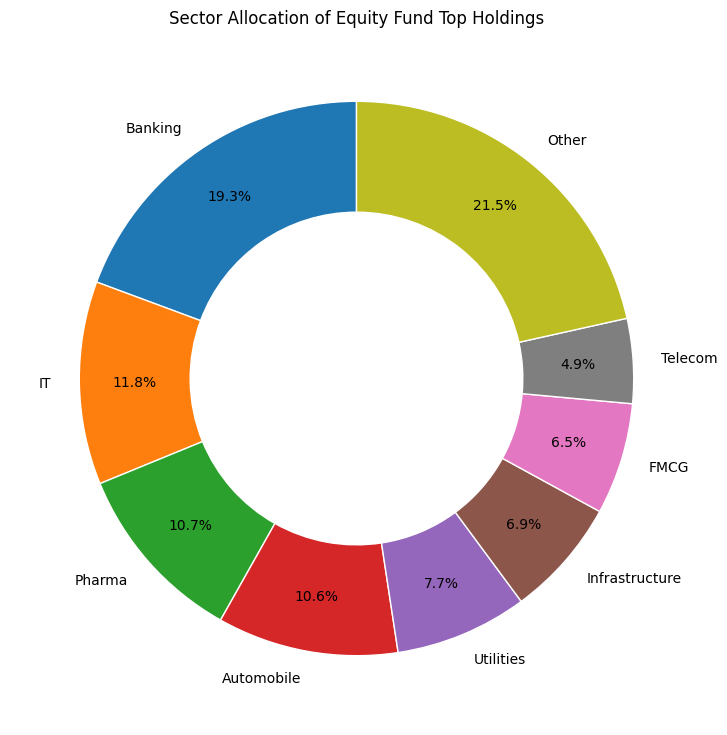

In [19]:
import seaborn as sns

hold = pd.read_sql_query(
    "SELECT amfi_code, sector, weight_pct, market_value_cr FROM fact_portfolio",
    conn
)
print("Holdings rows:", len(hold))
print("Funds covered:", hold["amfi_code"].nunique())

# Total market value per sector, and each sector's share
sector = hold.groupby("sector")["market_value_cr"].sum().sort_values(ascending=False)
share = (sector / sector.sum() * 100).round(1)
print()
print(share)

# Keep the 8 biggest sectors, group the rest as "Other"
top = sector.head(8).copy()
other = sector.iloc[8:].sum()
if other > 0:
    top["Other"] = other

fig, ax = plt.subplots(figsize=(9, 9))
ax.pie(top, labels=top.index, autopct="%1.1f%%", startangle=90,
       pctdistance=0.8, wedgeprops=dict(width=0.4, edgecolor="white"))
ax.set_title("Sector Allocation of Equity Fund Top Holdings")
fig.savefig(CHART_DIR / "09_sector_allocation.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding 10: Monthly transaction volume
Among the 5,000 investors in the dataset, lumpsum investments are the largest monthly flow (about Rs. 10.7 to 13.4 crore), followed by redemptions (about Rs. 6.2 to 8.4 crore). SIP amounts are small by value (about Rs. 1.2 to 1.4 crore a month) even though SIPs are the most frequent transaction type. Lumpsum inflows exceeded redemptions in every month shown, so net flows were positive. None of the three series shows a clear trend from Jan 2024 to about May 2025, which is unlike the steady rise in industry-wide SIP inflows in Finding 3, because this data covers only a simulated sample of investors.

transaction_type    Lumpsum  Redemption       SIP
month                                            
2025-01-01        11.829077    7.527125  1.308215
2025-02-01        10.673754    6.482191  1.136392
2025-03-01        12.803567    7.818237  1.344936
2025-04-01        11.957111    7.635476  1.213200
2025-05-01        12.007315    6.960821  1.397301


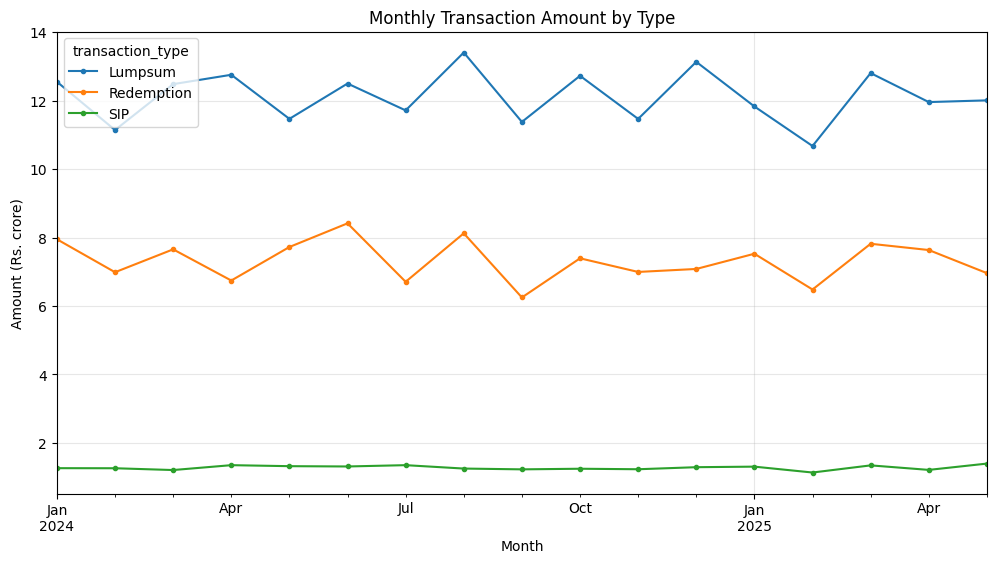

In [20]:
txm = pd.read_sql_query(
    "SELECT transaction_date, transaction_type, amount_inr FROM fact_transactions",
    conn, parse_dates=["transaction_date"]
)
txm["month"] = txm["transaction_date"].dt.to_period("M").dt.to_timestamp()

monthly = (txm.groupby(["month", "transaction_type"])["amount_inr"].sum()
              .unstack() / 1e7)          # Rs. crore
print(monthly.tail())

fig, ax = plt.subplots(figsize=(12, 6))
monthly.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Monthly Transaction Amount by Type")
ax.set_xlabel("Month")
ax.set_ylabel("Amount (Rs. crore)")
ax.grid(alpha=0.3)
fig.savefig(CHART_DIR / "10_monthly_transactions.png", dpi=150, bbox_inches="tight")
plt.show()

## EDA Summary: 10 Key Findings
1. Funds diverged sharply from 2022 to 2026: debt funds grew slowly (about 100 to 130), equity funds ranged from about 100 to over 350.
2. All 10 fund houses grew AUM every year; SBI roughly doubled to Rs. 12.5 lakh crore, and the top 3 hold about half of the top-10 total.
3. Monthly SIP inflow rose about 2.7 times, from about Rs. 11,500 crore to Rs. 31,002 crore.
4. Liquid funds dominate category inflows (Rs. 32,000 to 42,000 crore a month); no category had net outflows in FY 2024-25.
5. Investors aged 26-35 are the largest group (40.7%); the typical SIP is about Rs. 5,000 across all age groups.
6. SIP amounts are spread evenly across states (Madhya Pradesh and Punjab highest); T30 cities contribute 65.9% of the money.
7. Folios almost doubled, from 13.26 crore to 26.12 crore.
8. Fund returns in the dataset are almost uncorrelated, unlike real funds, so the data is partly synthetic.
9. Banking is the largest sector in top holdings (19.3%); the top four sectors make up about 52%.
10. Lumpsum is the largest monthly flow, redemptions are in the middle, and SIPs are small by value; net flows were positive.